# **Muhammad Ibtisam Afzal**

# Assignment No. 4: Data Preprocessing Using NumPy, Pandas & Seaborn

**Objective:** Create and preprocess a dataset of 20 students, calculate descriptive statistics, filter records, and visualize the data.

**Dataset note:** This is a synthetic teaching dataset. One Attendance value and one Marks value are intentionally missing. One duplicate row is added to demonstrate cleaning.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)

## 2. Create the 20-student dataset (Question 2)

In [2]:
data = {
    "Student Name": ["Ayesha","Bilal","Hina","Usman","Zara","Hamza","Noor","Ahmed","Maham","Daniyal","Fatima","Saad","Iqra","Talha","Laiba","Omar","Maryam","Kashif","Eman","Rayan"],
    "Age": [20,21,19,22,20,21,19,23,20,22,21,20,19,22,20,21,19,23,20,21],
    "Gender": ["Female","Male","Female","Male","Female","Male","Female","Male","Female","Male","Female","Male","Female","Male","Female","Male","Female","Male","Female","Male"],
    "Study Hours": [3.5,2.0,4.0,1.5,3.0,2.5,5.0,1.0,3.8,2.2,4.5,2.8,3.2,1.8,4.2,2.6,3.7,1.2,4.8,2.4],
    "Attendance": [92,78,96,70,88,82,98,65,94,80,97,85,90,74,95,83,np.nan,68,99,81],
    "Marks": [85,68,91,59,76,72,95,54,88,66,93,74,79,62,89,71,86,np.nan,97,69]
}
df = pd.DataFrame(data)
display(df)

,Student Name,Age,Gender,Study Hours,Attendance,Marks
0,Ayesha,20,Female,3.5,92.0,85.0
1,Bilal,21,Male,2.0,78.0,68.0
2,Hina,19,Female,4.0,96.0,91.0
3,Usman,22,Male,1.5,70.0,59.0
4,Zara,20,Female,3.0,88.0,76.0
5,Hamza,21,Male,2.5,82.0,72.0
6,Noor,19,Female,5.0,98.0,95.0
7,Ahmed,23,Male,1.0,65.0,54.0
8,Maham,20,Female,3.8,94.0,88.0
9,Daniyal,22,Male,2.2,80.0,66.0


## 3. Inspect missing values and duplicate records

In [3]:
# Add one intentional duplicate row for demonstration.
df = pd.concat([df, df.iloc[[0]]], ignore_index=True)
print("Shape before cleaning:", df.shape)
print("Missing values by column:")
display(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Shape before cleaning: (21, 6)
Missing values by column:


,0
Student Name,0
Age,0
Gender,0
Study Hours,0
Attendance,1
Marks,1


Duplicate rows: 1


## 4. NumPy array and descriptive statistics (Question 1)

Statistics are calculated after removing the duplicate and imputing missing numeric values. Population standard deviation is used (`ddof=0`).

In [4]:
df_clean = df.drop_duplicates().copy()
df_clean["Attendance"] = df_clean["Attendance"].fillna(df_clean["Attendance"].median())
df_clean["Marks"] = df_clean["Marks"].fillna(df_clean["Marks"].median())

marks_array = np.array(df_clean["Marks"], dtype=float)
print("Marks array:", marks_array)
print(f"Mean: {np.mean(marks_array):.2f}")
print(f"Median: {np.median(marks_array):.2f}")
print(f"Population standard deviation: {np.std(marks_array):.2f}")

Marks array: [85. 68. 91. 59. 76. 72. 95. 54. 88. 66. 93. 74. 79. 62. 89. 71. 86. 76.
 97. 69.]
Mean: 77.50
Median: 76.00
Population standard deviation: 12.25


## 5. Final Pandas DataFrame (Question 2)

In [5]:
display(df_clean)
print('Cleaned DataFrame shape:', df_clean.shape)

,Student Name,Age,Gender,Study Hours,Attendance,Marks
0,Ayesha,20,Female,3.5,92.0,85.0
1,Bilal,21,Male,2.0,78.0,68.0
2,Hina,19,Female,4.0,96.0,91.0
3,Usman,22,Male,1.5,70.0,59.0
4,Zara,20,Female,3.0,88.0,76.0
5,Hamza,21,Male,2.5,82.0,72.0
6,Noor,19,Female,5.0,98.0,95.0
7,Ahmed,23,Male,1.0,65.0,54.0
8,Maham,20,Female,3.8,94.0,88.0
9,Daniyal,22,Male,2.2,80.0,66.0


Cleaned DataFrame shape: (20, 6)


## 6. Identify and handle missing values (Question 3)

In [6]:
print("Missing values before handling:")
display(df.isnull().sum())
print("Missing values after median imputation:")
display(df_clean.isnull().sum())

Missing values before handling:


,0
Student Name,0
Age,0
Gender,0
Study Hours,0
Attendance,1
Marks,1


Missing values after median imputation:


,0
Student Name,0
Age,0
Gender,0
Study Hours,0
Attendance,0
Marks,0


## 7. Find and remove duplicate records (Question 4)

In [7]:
print("Duplicate rows detected:", df.duplicated().sum())
df_no_duplicates = df.drop_duplicates().copy()
print("Shape after duplicate removal:", df_no_duplicates.shape)
print("Remaining duplicates:", df_no_duplicates.duplicated().sum())

Duplicate rows detected: 1
Shape after duplicate removal: (20, 6)
Remaining duplicates: 0


## 8. Filter students scoring more than 70 (Question 5)

In [8]:
students_above_70 = df_clean[df_clean["Marks"] > 70].sort_values("Marks", ascending=False)
display(students_above_70[["Student Name", "Marks"]])
print("Number of students scoring more than 70:", len(students_above_70))

,Student Name,Marks
18,Eman,97.0
6,Noor,95.0
10,Fatima,93.0
2,Hina,91.0
14,Laiba,89.0
8,Maham,88.0
16,Maryam,86.0
0,Ayesha,85.0
12,Iqra,79.0
4,Zara,76.0


Number of students scoring more than 70: 14


## 9. Study hours vs marks using Seaborn (Question 6)

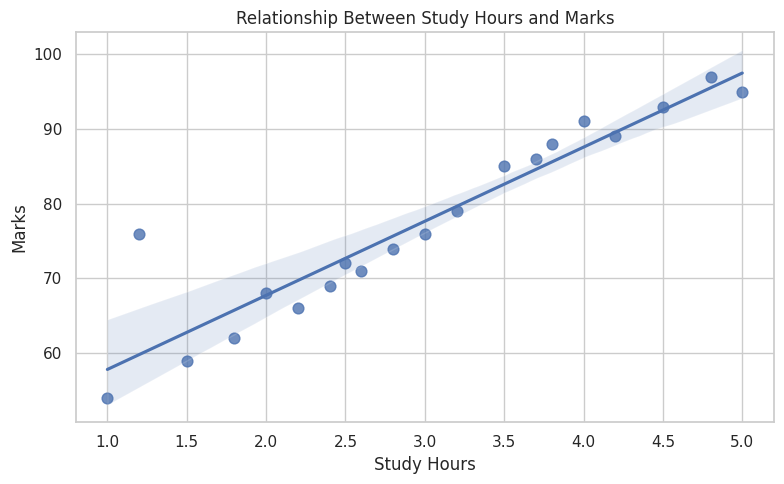

In [9]:
plt.figure(figsize=(8,5))
sns.regplot(data=df_clean, x="Study Hours", y="Marks", scatter_kws={"s":60, "alpha":0.8})
plt.title("Relationship Between Study Hours and Marks")
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.tight_layout()
plt.show()

## 10. Histogram of marks (Question 7)

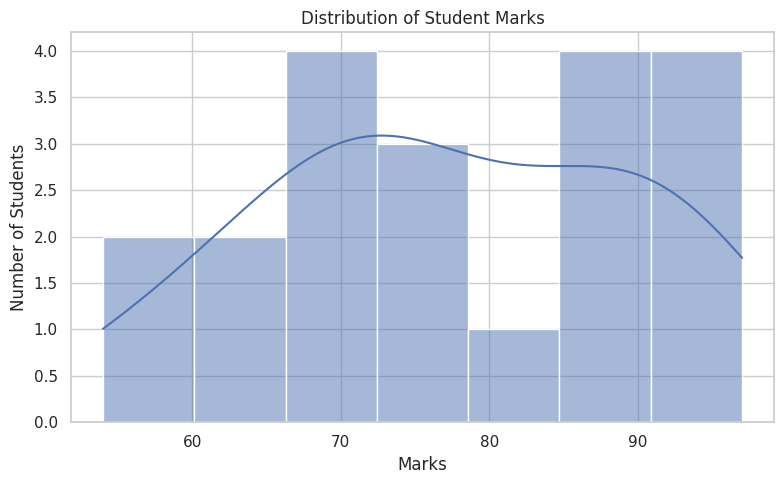

In [10]:
plt.figure(figsize=(8,5))
default_color = plt.rcParams["axes.prop_cycle"].by_key()["color"][0]
sns.histplot(data=df_clean, x="Marks", bins=7, kde=True, color=default_color)
plt.title("Distribution of Student Marks")
plt.xlabel("Marks")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

## 11. Interpretation and conclusion

In [11]:
correlation = df_clean["Study Hours"].corr(df_clean["Marks"])
print(f"Pearson correlation: {correlation:.3f}")
print("A positive correlation indicates that students who study more hours tend to achieve higher marks in this sample.")
print("Correlation does not prove causation.")

Pearson correlation: 0.936
A positive correlation indicates that students who study more hours tend to achieve higher marks in this sample.
Correlation does not prove causation.


**Conclusion:** NumPy was used for descriptive statistics, Pandas for DataFrame creation and preprocessing, and Seaborn for the two required visualizations. Missing numeric values were replaced with column medians, and the duplicate row was removed.